# Multimodal Requests & Streaming 

## Introduction  

This notebook introduces the **Anthropic Messages API** and shows **how Claude can process different types of content in a single request**. We start with **simple text prompts**, then move to **structured content blocks**, **image inputs**, and **multimodal requests**. By the end, you’ll get a view how to combine text and images in one message and stream Claude’s response as it is generated.  


##  Setup  

Before making our first request to Claude, we need to prepare the Python environment and initialize the Anthropic client.  It begins by importing the Anthropic SDK, loading the API credentials, selecting a model, and initializing the Anthropic client.   

### Import SDK  
 The anthropic package provides the Python SDK for interacting with Claude through the Anthropic API. 

In [22]:
# Import the Anthropic SDK client.
from anthropic import Anthropic

### Load credentials  
  
This repository uses environment variables to keep the Anthropic API key separate from the code. The provided helper function (`helper.py`) loads the variables from the local `.env` file (see `.env_example` file).  

In [23]:
# Load environment variables such as ANTHROPIC_API_KEY
from helper import load_env
load_env()

### Initialize client  

Once the environment variable has been loaded, an `Anthropic client` should be created. This Anthropic client will use the `Anthropic API key` environment variable when making API requests.

In [24]:
# Initialize the Anthropic client
client = Anthropic()

### Select a model  

The Anthropic API provides access to [different Claude models](https://platform.claude.com/docs/en/models/overview), each designed for different types of tasks and workloads. The model identifier is stored in a variable so that it can be reused throughout the notebook.

In [25]:
# Example model configuration.
MODEL_NAME="claude-sonnet-5"   

## Content Blocks

Claude messages can contain content in two forms:  
  
- a **plain string**, which is the simplest and most readable option for text-only prompts  
- a **list of content blocks**, which provides a structured format for combining different types of content  

The structured format becomes especially useful when we move beyond text and start working with images, thus combining text with images. 

### Simple Text Content  

For a basic text-only request, the content field can be a **plain string**, which is readable and easy to use for basic prompts, such as tasks like short jokes or Q&A:  

In [26]:
messages = [
    {
        "role": "user",
        "content": "tell me a joke"
    }
]

response = client.messages.create(
    messages=messages,
    model=MODEL_NAME,
    max_tokens=200
)  

# The assistant response is returned as a structured message object.
# response.content[0].text accesses the first text block in the reply.
print(response.content[0].text)

Why don't scientists trust atoms?

Because they make up everything!


**Explanation output** This code demonstrates the simplest input format accepted by the API: a plain string inside the content field. The call to `client.messages.create()` is the core API interaction, and the output is printed directly.      

### Structured Text Content 

The same prompt can also be represented as a structured content block:

In [27]:
messages = [
    {
        "role": "user",
        "content": [
            {"type": "text", "text": "tell me a joke"},
        ]
    }
]

response = client.messages.create(
    messages=messages,
    model=MODEL_NAME,
    max_tokens=200
)
print(response.content[0].text)

Here's one for you:

Why don't scientists trust atoms?

Because they make up everything!

Want another one?


**Explanation output** The prompt itself has not changed. The difference is that content is now a list containing a typed content block.

>_Key idea:_ Use a `plain string` when a simple text prompt is enough. Use `structured content` blocks when you need to combine or explicitly represent different types of content.

### Multiple Content Blocks  

A message can contain **multiple content blocks**. This allows us to build a prompt from separate pieces of content.

In [28]:
messages = [ 
    { "role": "user",
      "content": [ 
          { "type": "text", "text": "You are helping me analyze an image." },
          { "type": "text", "text": "Describe the main objects and explain what is happening." } 
          ] 
    } 
] 
response = client.messages.create( 
    messages=messages, 
    model=MODEL_NAME,
      max_tokens=200 
)
print(response.content[0].text)

I'd be happy to help analyze an image for you! However, I don't see an image attached to your message. 

Could you please upload or attach the image you'd like me to describe? Once you share it, I'll provide details about:

- The main objects and subjects present
- The setting or context
- What appears to be happening in the scene
- Any other relevant details you're interested in

Please go ahead and share the image whenever you're ready.


In this example, both blocks are text, but they represent separate parts of the prompt.  

The real value of this structure becomes apparent when different content types are combined. For example, a single message can contain a text instruction followed by an image:  

```  
Text instruction
      ↓
Image
      ↓
Text instruction  
```  

We will use this pattern in the next section to send images to Claude.  

**Key Takeaway**  The three formats we have seen are progressively more flexible:  

| Format                   | Example                    | Use case                                  |
|--------------------------|----------------------------|-------------------------------------------|
| Plain string             | `"tell me a joke"`         | Simple text prompts                       |
| One content block        | `{"type": "text", ...}`    | Explicit structured content              |
| Multiple content blocks  | `[text, text, ...]`        | Composing richer or multimodal messages   |

The important concept is not that one format is always better than another. Instead, structured content blocks give us the flexibility to extend a simple text message into a multimodal request.

This example shows that prompts can be composed from multiple fragments instead of one complex string. It is a useful pattern when you want to build a message step by step, especially as prompts become more detailed or multimodal.

## Image Prompts (Image Inputs)  

Claude can process images when they are included as part of a structured message.  

In this section, we will build an image request step by step:  

- inspect the image we want to send  
- prepare the image for the API request  
- send the image to Claude  
- combine the image with a text instruction  

This will build on the structured content blocks introduced in the previous section.  


Inspecting the image first helps us understand what we are asking Claude to analyze.  

### Prepare the Image  

When an image is sent through the API, it needs to be represented in a format that can be included in an image content block.  

For this example, we will use a `Base64-encoded image`.  

The process is:  

- Read the image as binary data.  
- Encode the binary data as Base64.  
- Convert the encoded data to a string.  
- Include the string in the image content block.  

In [29]:
import base64
# opens the image file in "read binary" mode
with open("images/packages2.png", "rb") as image_file:
    #reads the contents of the image as a bytes object
    binary_data = image_file.read() 
    #encodes the binary data using Base64 encoding
    base_64_encoded_data = base64.b64encode(binary_data) 
    #decodes base_64_encoded_data from bytes to a string
    base64_string = base_64_encoded_data.decode('utf-8')

We can inspect the beginning of the encoded value to confirm that the image has been converted to a string:

In [30]:
base64_string[:100]

'iVBORw0KGgoAAAANSUhEUgAAF7IAAA/MCAIAAAApRc8vAAEAAElEQVR4nOz9iZrjuo4sjGrwkLX2OX3/93/M092rMm1Luh8JKhQK'

In [31]:
from PIL import Image
import io
import base64

image_path = "images/packages2.png"

# Open your original image
img = Image.open(image_path)

# Convert to RGB or RGBA if necessary
if img.mode not in ("RGB", "RGBA"):
    img = img.convert("RGBA" if "transparency" in img.info else "RGB")

# Resize if necessary
img.thumbnail((2000, 2000))

# Compress the image into memory as PNG
buffer = io.BytesIO()
img.save(buffer, format="PNG", optimize=True)

# Encode the compressed image in Base64
image_base64 = base64.b64encode(buffer.getvalue()).decode("utf-8")

print(f"Compressed PNG size: {len(buffer.getvalue()) / (1024 * 1024):.2f} MiB")

Compressed PNG size: 1.54 MiB


In [32]:
if len(buffer.getvalue()) > 10 * 1024 * 1024:
    raise ValueError("Image exceeds the 10 MiB limit. Resize it further.")

In [33]:
print("Image dimensions:", img.size)
print("PNG bytes:", len(buffer.getvalue()))
print("Stop reason:", response.stop_reason)
print("Usage:", response.usage)

for block in response.content:
    print("Block type:", block.type)

Image dimensions: (2000, 1333)
PNG bytes: 1612860
Stop reason: end_turn
Usage: Usage(cache_creation=CacheCreation(ephemeral_1h_input_tokens=0, ephemeral_5m_input_tokens=0), cache_creation_input_tokens=0, cache_read_input_tokens=0, input_tokens=32, output_tokens=132, server_tool_use=None, service_tier='standard', output_tokens_details={'thinking_tokens': 0}, inference_geo='global', speed='standard')
Block type: text


In [34]:
# Save the compressed image to disk
output_path = "images/packages2_compressed.png"
with open(output_path, "wb") as f:
    f.write(buffer.getvalue())

print(f"Saved to: {output_path}")

Saved to: images/packages2_compressed.png


### Inspect the Image  

Before sending an image to Claude, let's take a look at the image we will use.

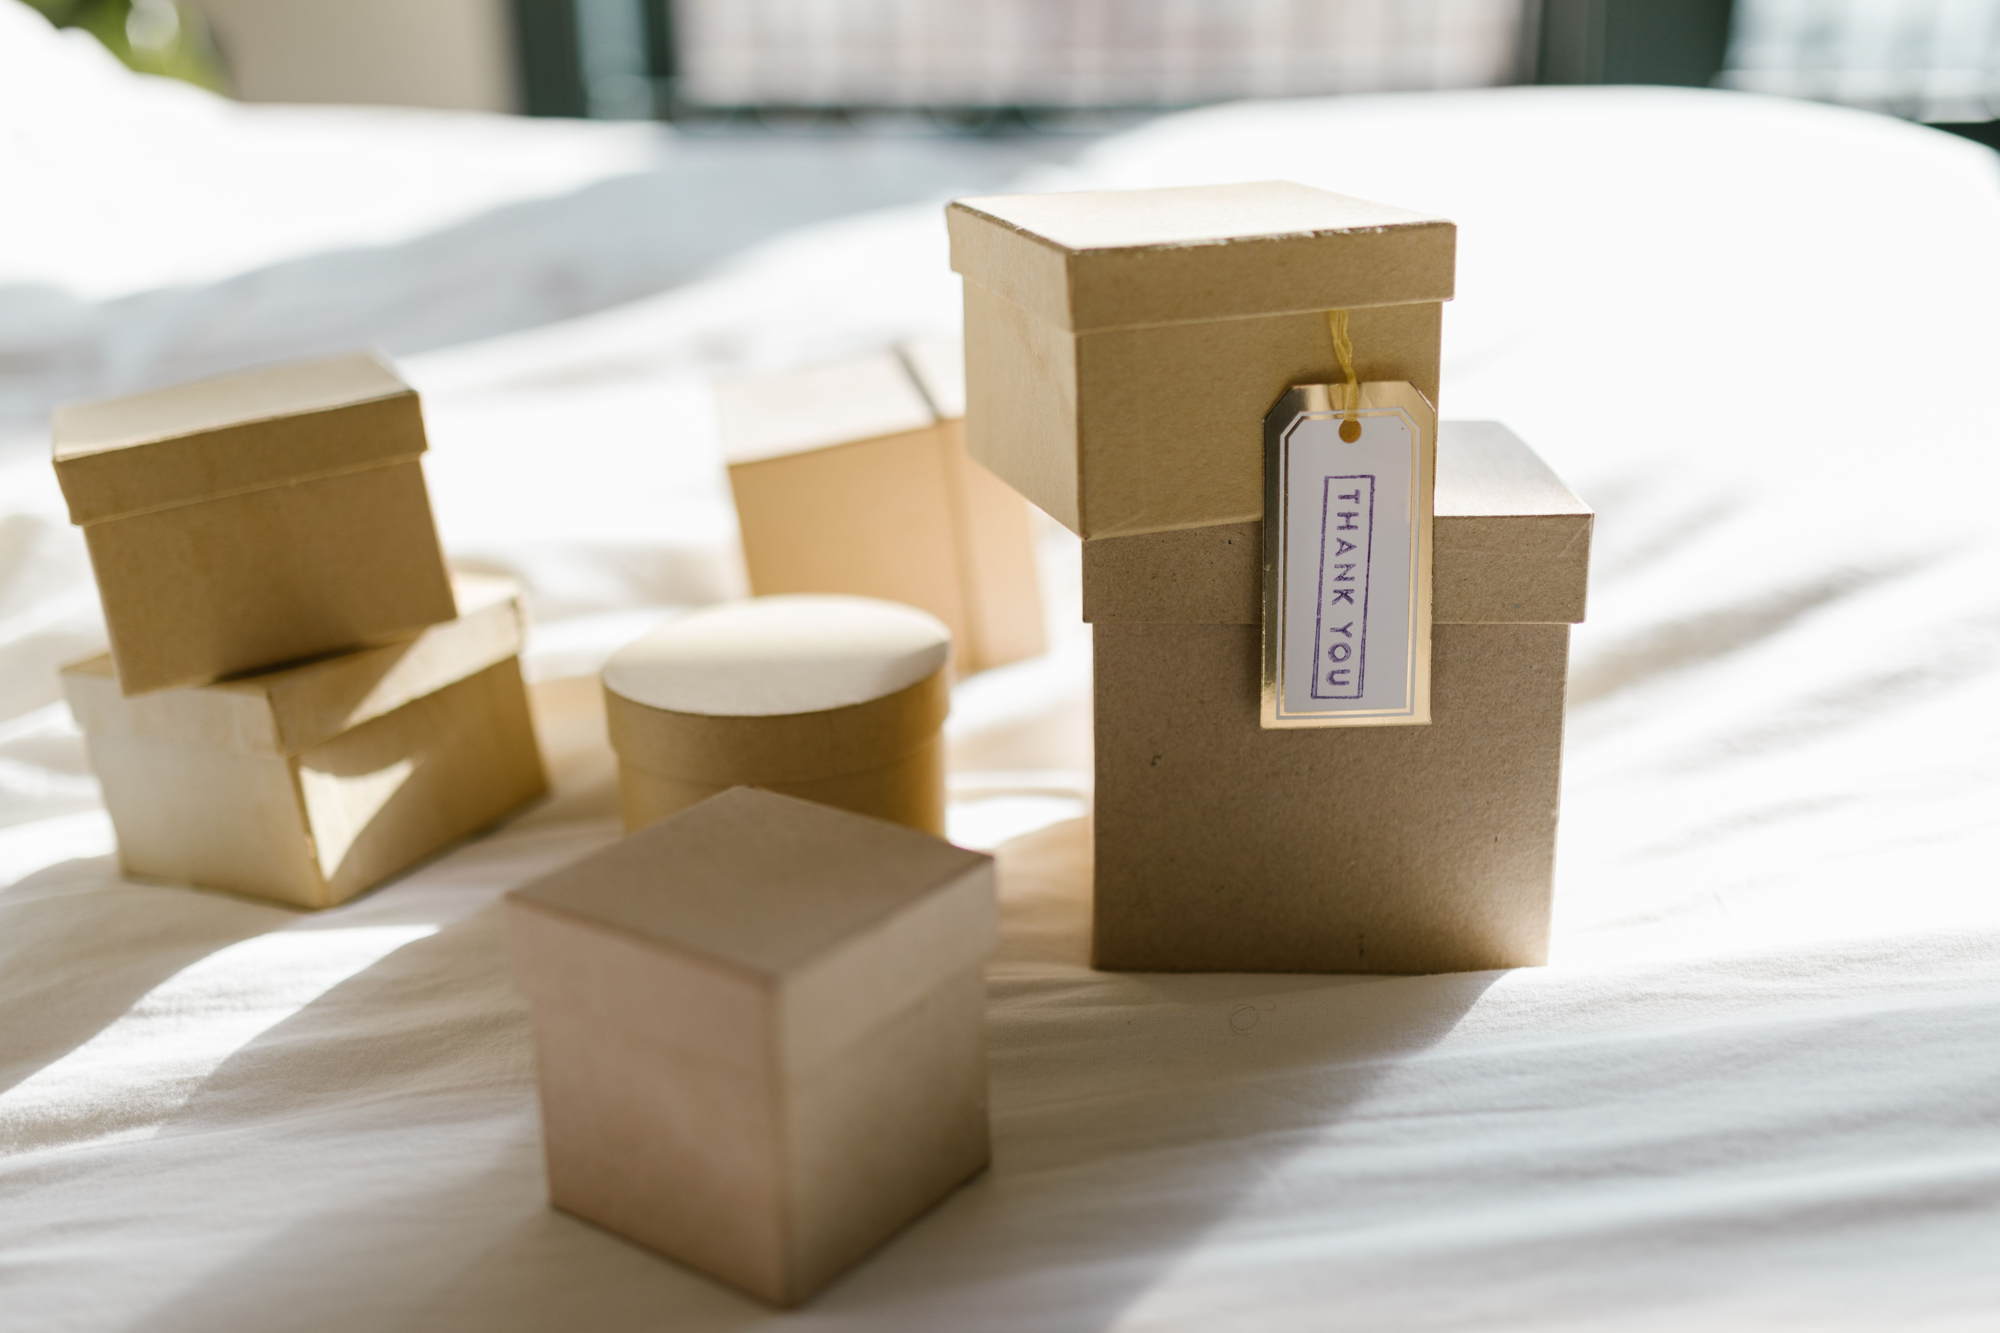

In [35]:
from IPython.display import Image
#Image(filename='images/packages2.png')
Image(filename='images/packages2_compressed.png') 

### Send an Image to Claude  

We can now include the encoded image in a structured content block.  

An image content block specifies:  

- the content type  
- the image source  
- the image media_type  
- the Base64-encoded image data    

At this point, we have sent an image to Claude. However, an image by itself does not tell Claude what we want it to do with the image.

We can make the request more useful by adding a text instruction.

### Combine Image and Text  

Because messages can contain multiple content blocks, we can combine an image with a text instruction in the same message.  

In [36]:
messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "source": {
                    "type": "base64",
                    "media_type": "image/png",
                    "data": image_base64
                }
            },
            {
                "type": "text",
                #"text": "Describe this image."
                "text": """How many boxes of each type 
            are in this image?"""
            }
        ]
    }
]

response = client.messages.create(
    model=MODEL_NAME,
    max_tokens=2048,
    #max_tokens=200,
    messages=messages
)

text_blocks = [
    block.text
    for block in response.content
    if getattr(block, "type", None) == "text"
]

if text_blocks:
    print("\n".join(text_blocks))
elif response.stop_reason == "max_tokens":
    print("No text was returned: the token limit was reached during reasoning.")
else:
    print("The response contains no text block.")

Looking at the image, I can identify the following boxes on the white bed:

**Square/Cube boxes (with lids): 6 total**
- 2 stacked together on the left side (one appears slightly open)
- 1 small cube box in the front center
- 1 tan/beige box partially visible in the back middle
- 2 stacked together on the right side (with the "THANK YOU" gift tag attached)

**Round/Cylindrical box: 1 total**
- 1 round box with a cream-colored lid, positioned in the middle

**Summary:**
| Box Type | Count |
|----------|-------|
| Square/Cube boxes | 6 |
| Round boxes | 1 |
| **Total** | **7** |

These appear to be decorative gift/storage boxes in gold and kraft paper tones, likely used for wedding favors or gift packaging, given the "Thank You" tag attached to one of the stacks.


The message now contains two content blocks:

```
Text instruction
      +
    Image
      ↓
    Claude
      ↓
Generated response  
```  

This is the basic pattern for a multimodal request: provide an image and tell Claude what you want it to do with that image.

##  Reusable Image Helper    

The previous example showed all the steps required to prepare an image manually. That is useful for understanding the API, but we would not want to repeat that code every time we send an image.

Let's turn those steps into a reusable helper function.

### Create the Helper (Image Block Helper Function)    

In [37]:
import base64
import mimetypes

def create_image_message(image_path):
    # Open the image file in "read binary" mode
    with open(image_path, "rb") as image_file:
        # Read the contents of the image as a bytes object
        binary_data = image_file.read()
    # Encode the binary data using Base64 encoding
    base64_encoded_data = base64.b64encode(binary_data)
    # Decode base64_encoded_data from bytes to a string
    base64_string = base64_encoded_data.decode('utf-8')
    # Get the MIME type of the image based on its file extension
    mime_type, _ = mimetypes.guess_type(image_path)
    # Create the image block
    image_block = {
        "type": "image",
        "source": {
            "type": "base64",
            "media_type": mime_type,
            "data": base64_string
        }
    }
    
    
    return image_block

### Use the Helper

Now we can create an image content block with a single function call. In the below example shows up a demo image that is a terminal showing a Python script that fails while totalling an invoice CSV

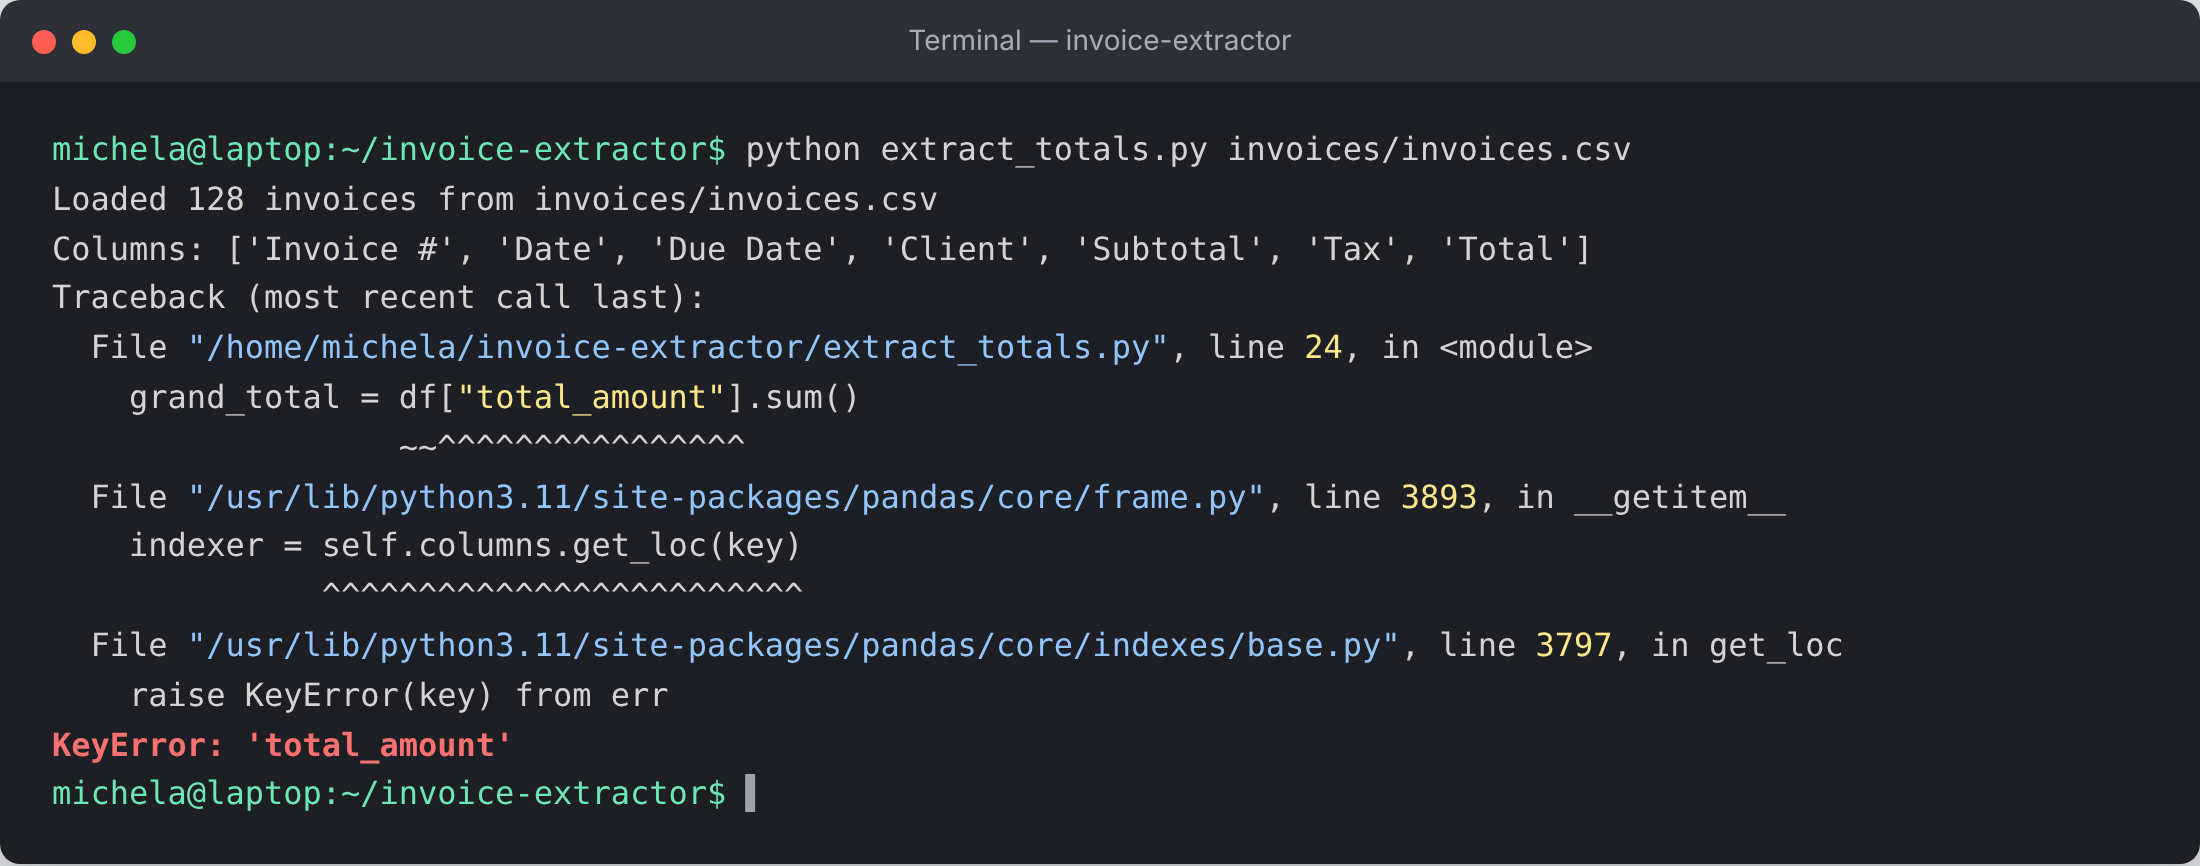

In [38]:
from IPython.display import Image as DisplayImage, display
display(DisplayImage(filename="images/error_screenshot_example.png"))

In the below snippet code, it is displayed the sample prompt ( “What’s going on in this screenshot, and how do I fix it?”) used to pair with it and the kind of answer Claude would give.

In [39]:
messages = [
    {
        "role": "user",
        "content": [
            create_image_message("./images/error_screenshot_example.png"),
            {"type": "text", "text": "What’s going on in this screenshot, and how do I fix it?"}
        ]
    }
]

response = client.messages.create(
    model=MODEL_NAME,
    max_tokens=2048,
    messages=messages
)
print(response.content[0].text)

# What's happening

Your script is trying to access a column called `"total_amount"`, but based on the printed column list:

```
Columns: ['Invoice #', 'Date', 'Due Date', 'Client', 'Subtotal', 'Tax', 'Total']
```

There is no column named `total_amount` in the CSV — the actual column is named **`Total`** (capitalized, no underscore). Pandas column lookups are case-sensitive and exact-match, so `df["total_amount"]` raises a `KeyError` because that key simply doesn't exist.

# The fix

In `extract_totals.py`, line 24, change:

```python
grand_total = df["total_amount"].sum()
```

to:

```python
grand_total = df["Total"].sum()
```

## Optional: make it more robust

If your CSV column names might vary between files (e.g., sometimes `Total`, sometimes `total_amount`), you can normalize the columns right after loading:

```python
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
```

This would turn `Total` into `total`, `Invoice #` into `invoice_#`, etc. Then reference 

**Explanation output**: The example works well in the demo because the answer goes beyond describing the image: it connects two separate lines on screen (the requested column and the actual column list), explains the cause, gives working fixes, and anticipates the next likely error.

##  Real-World Use Case: Invoice Extraction    

Multimodal models become especially useful when information exists in documents or images rather than plain text.

In this example, we will:   

1. provide Claude with an invoice image  
2. ask it to identify specific fields  
3. request the result as JSON  
4. inspect the generated response  


### Inspect the Invoice  

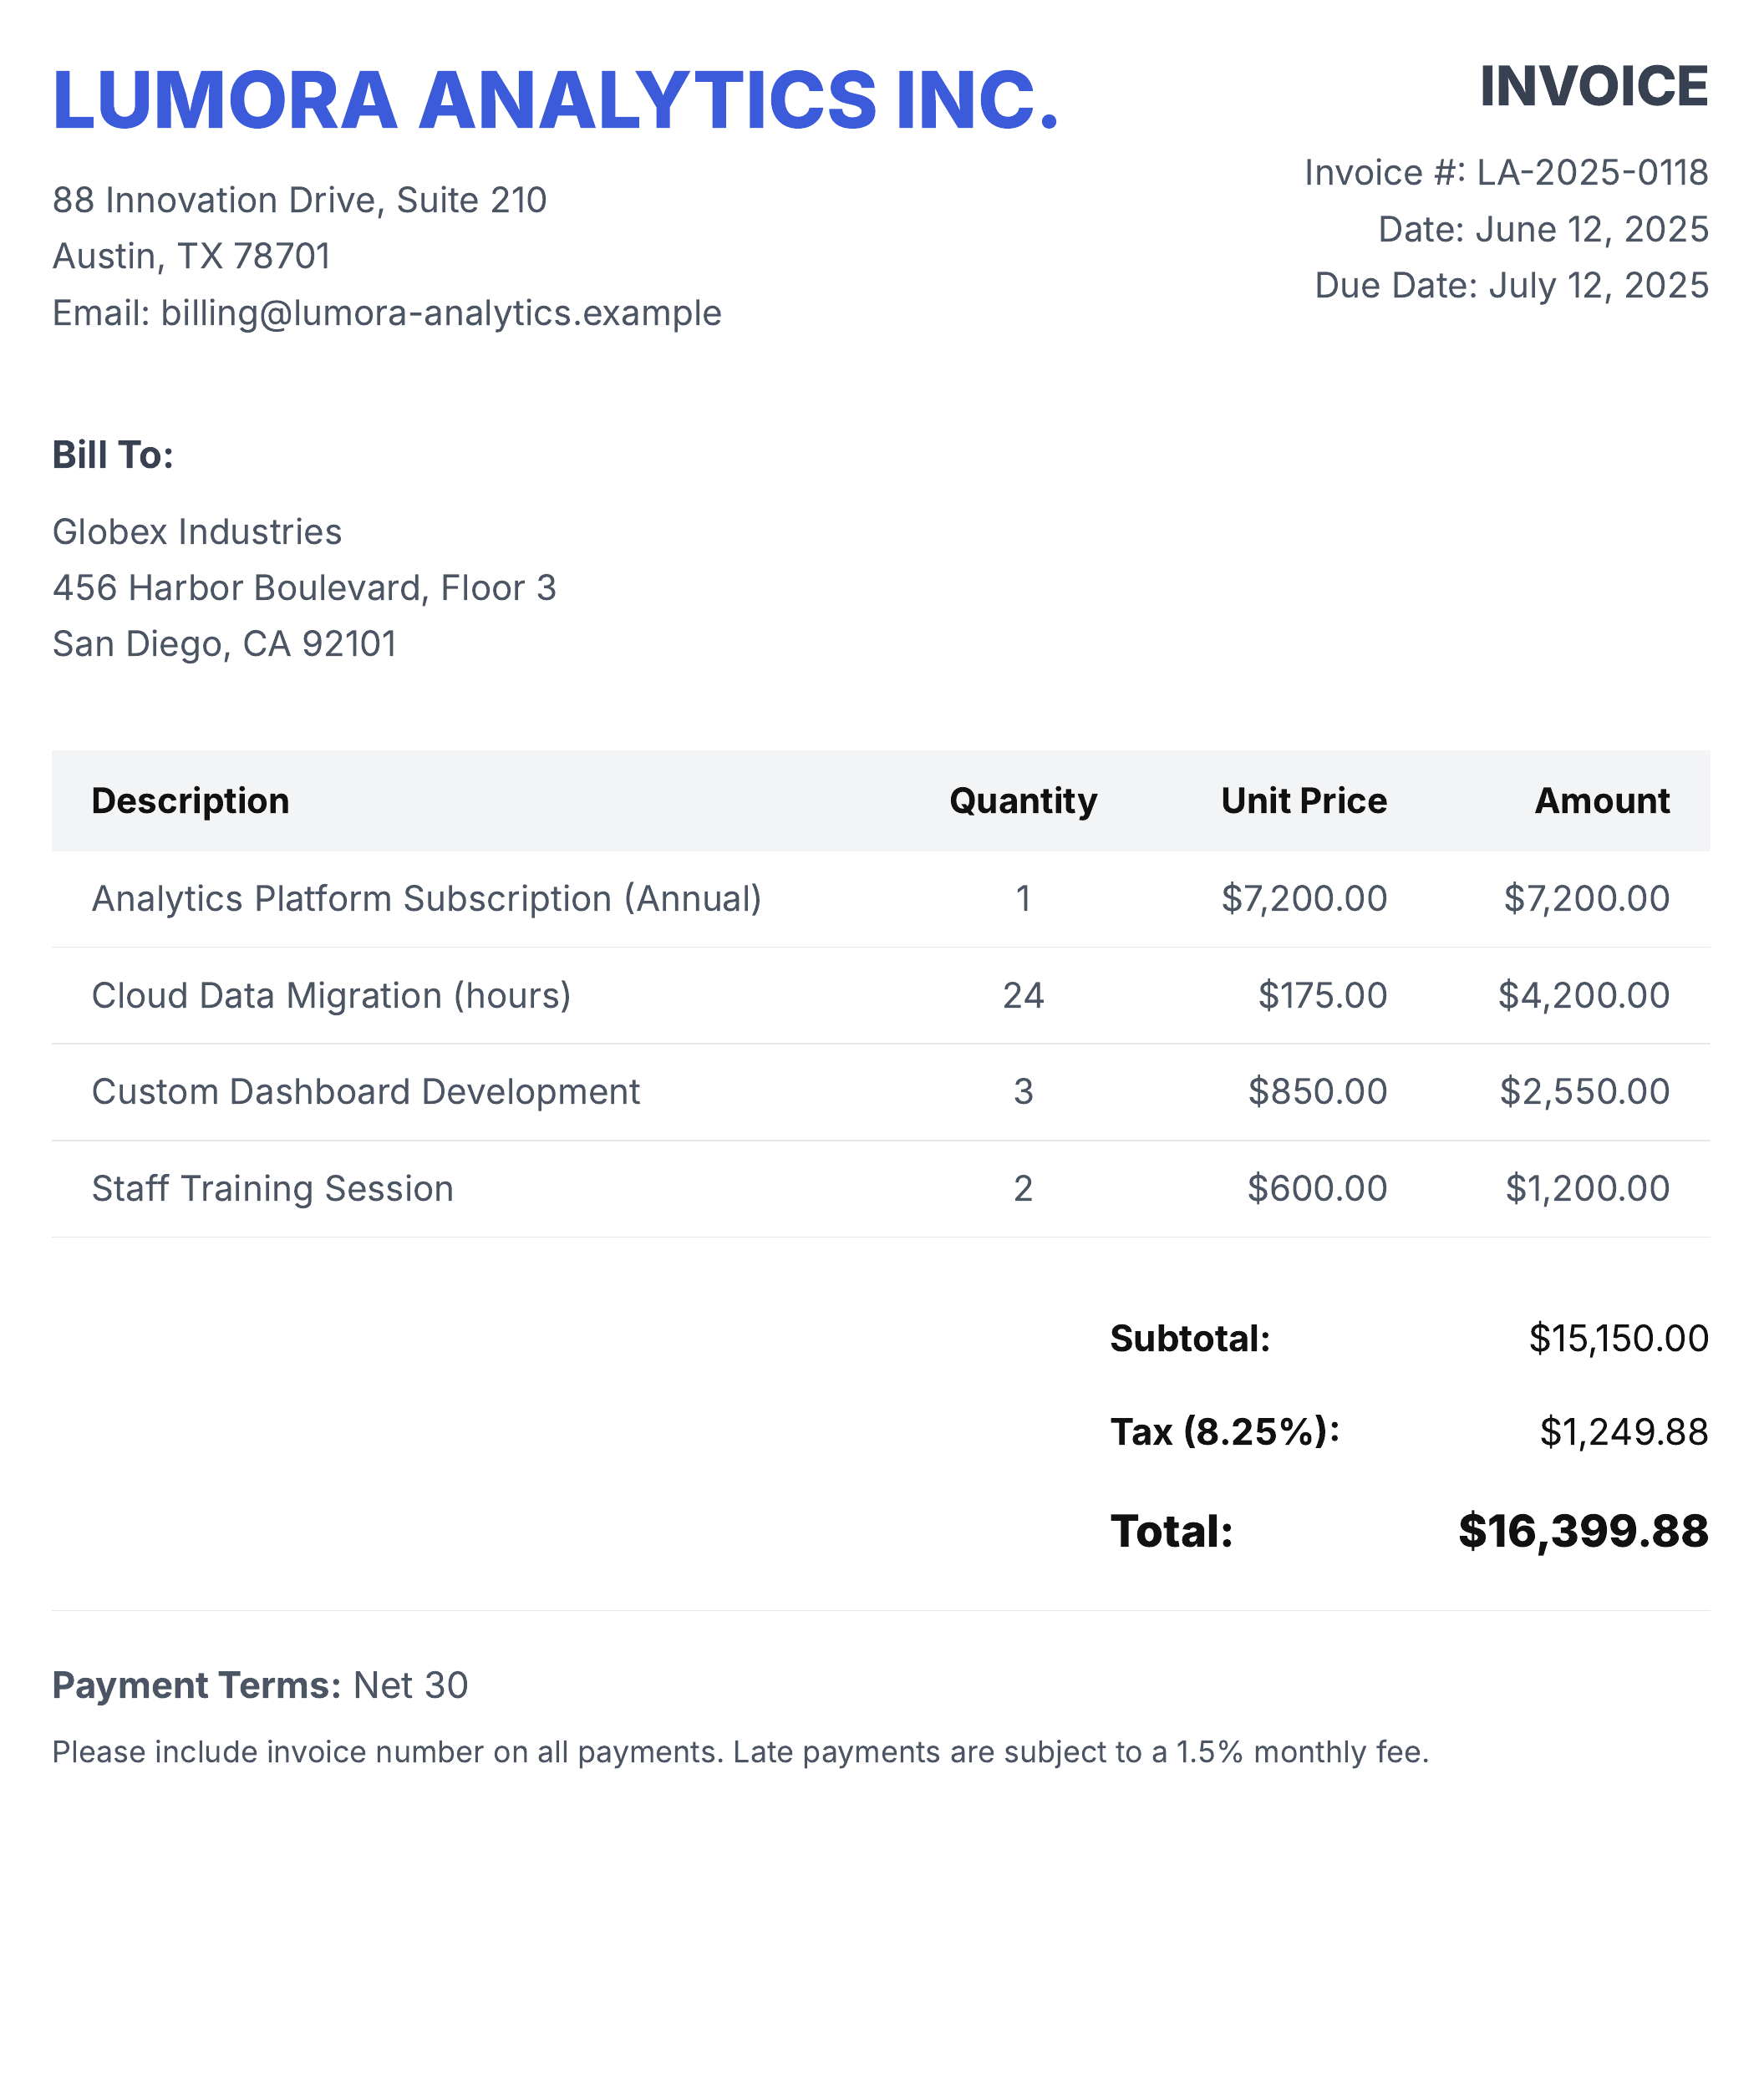

In [40]:
from IPython.display import Image as DisplayImage, display
display(DisplayImage(filename="images/invoice_example.png"))

### Build the Request & Extract Structured Information

In [41]:
messages = [
    {
        "role": "user",
        "content": [
            create_image_message("./images/invoice_example.png"),
            {"type": "text", "text": """
                Generate a JSON object representing the contents
                of this invoice.  It should include all dates,
                dollar amounts, and addresses. 
                Only respond with the JSON itself.
            """
            }
        ]
    }
]

#response = client.messages.create(
    #model=MODEL_NAME,
    #max_tokens=2048,
    #messages=messages
#)
#print(response.content[0].text)


response = client.messages.create(
    model=MODEL_NAME,
    max_tokens=4096,
    messages=messages
)

text_blocks = [
    block.text
    for block in response.content
    if block.type == "text"
]

if text_blocks:
    print("\n".join(text_blocks))
else:
    print("No text answer was returned.")
    print("Stop reason:", response.stop_reason)
    print("Usage:", response.usage)




```json
{
  "invoice": {
    "number": "LA-2025-0118",
    "date": "June 12, 2025",
    "due_date": "July 12, 2025",
    "payment_terms": "Net 30",
    "late_fee_note": "Late payments are subject to a 1.5% monthly fee."
  },
  "from": {
    "name": "Lumora Analytics Inc.",
    "address": {
      "street": "88 Innovation Drive, Suite 210",
      "city": "Austin",
      "state": "TX",
      "zip": "78701"
    },
    "email": "billing@lumora-analytics.example"
  },
  "bill_to": {
    "name": "Globex Industries",
    "address": {
      "street": "456 Harbor Boulevard, Floor 3",
      "city": "San Diego",
      "state": "CA",
      "zip": "92101"
    }
  },
  "line_items": [
    {
      "description": "Analytics Platform Subscription (Annual)",
      "quantity": 1,
      "unit_price": 7200.00,
      "amount": 7200.00
    },
    {
      "description": "Cloud Data Migration (hours)",
      "quantity": 24,
      "unit_price": 175.00,
      "amount": 4200.00
    },
    {
      "description": "C

##  Streaming   

By default, thus without Streaming, the application waits until Claude has generated the response before displaying it. Streaming allows to process the response incrementally as it becomes available. The following table diplays the main differences between the two scenarios. 

| Scenario | Meaning |
|------|---------|
| _Without streaming:_ | Request → [wait...] → Complete response |
| _With streaming:_ | Request → Response chunk → Response chunk → Response chunk → ... |


### Standard Response  (Without Streaming)  

In [42]:
response = client.messages.create(
    max_tokens=1024,
    messages=[{"role": "user", "content": "write a poem"}],
    model=MODEL_NAME,
)
print(response.content[0].text)

# Morning Light

The dawn breaks soft through window panes,
A gentle wash of gold and grey,
While shadows stretch their sleepy frames
And night surrenders to the day.

The birds begin their morning song,
A chorus bright with hopeful sound,
As dew drops cling to grass blades long
And silence lifts without a bound.

Each day arrives both new and old,
A page unwritten, clean and bright,
With stories yet to be retold
And moments waiting for the light.

So greet the morning, heart held true,
For time is brief, and skies are wide—
There's so much waiting here for you
Beyond the dawn, on either side.


**Explanation output** The application waits for the complete response before printing it.

### With Streaming

In [43]:
with client.messages.stream(
    max_tokens=1024,
    messages=[{"role": "user", "content": "write a poem"}],
    model=MODEL_NAME,
) as stream:
  for text in stream.text_stream:
      print(text, end="", flush=True)

**Autumn's Quiet Hour**

The evening settles soft and slow,
Where amber leaves drift down below,
A gentle wind begins to hum,
As twilight whispers, day is done.

The stars emerge, one by one,
To watch the setting of the sun,
And in this calm, this fleeting peace,
The restless heart finds its release.

Tomorrow waits beyond the night,
But now we rest in fading light,
For every ending holds a start—
A quiet hope within the heart.

**Explanation output**: With streaming, text is displayed as it arrives.

## Conclusion 

In this notebook, we moved from basic text prompts to multimodal requests using Claude. The main key points to keep on mind are the following:

- A message can contain a simple text string or structured content blocks.
- Structured content blocks allow text and images to be combined in a single request.
- Images can be prepared and reused through a helper function.
- Multimodal requests can be used for practical tasks such as extracting information from documents.
- Streaming allows applications to display generated text incrementally rather than waiting for the complete response.

Together, these patterns provide a flexible foundation for building more capable AI applications that work with multiple content types.


##  Extra Practice  

The following challenges are designed to reinforce the main concepts from this notebook. 

### Challenge 1: Content Blocks    

- **Compare a plain string and structured text block**    

In [ ]:
## Snippet code example

plain_prompt = "Explain recursion in 2 sentences."

structured_prompt = [
    {
        "role": "user",
        "content": [
            {"type": "text", "text": "Explain recursion in 2 sentences."}
        ]
    }
]

response_plain = client.messages.create(
    model=MODEL_NAME,
    max_tokens=100,
    messages=[{"role": "user", "content": plain_prompt}]
)

response_structured = client.messages.create(
    model=MODEL_NAME,
    max_tokens=100,
    messages=structured_prompt
)

print("Plain:", response_plain.content[0].text)
print("Structured:", response_structured.content[0].text)

- **Create a message using multiple content blocks**  

  > Tip 1_: Your message should contain for instance a text instruction asking Claude to analyze an image, an image content block and last but not least a second text instruction asking Claude to focus on a specific aspect of the image.     
  > Tip 2_: Experiment with changing the instructions and observe how the response changes.

In [ ]:
## Snippet code example
messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "text",
                "text": "Analyze the image and describe what you see."
            },
            {
                "type": "image",
                "source": {
                    "type": "base64",
                    "media_type": "image/png",
                    "data": base64_string
                }
            },
            {
                "type": "text",
                "text": "Focus especially on the main objects in the image."
            }
        ]
    }
]

response = client.messages.create(
    model=MODEL_NAME,
    max_tokens=300,
    messages=messages
)

print(response.content[0].text)

### Challenge 2: Image Analysis (Multimodal prompt)   

Choose another image from the `images/ directory`,  send it to Claude and ask then to:  
- identify the main objects in the image  
- describe what is happening  
- provide the response as a short list  

>_Tip_: Use the `create_image_message()` helper from the previous section rather than repeating the Base64 encoding code.   

In [ ]:
## Snippet code example
image_message = create_image_message("./images/plant.png")

messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "text",
                "text": """
                Analyze this image.

                1. Identify the main objects.
                2. Describe what is happening.
                3. Return your answer as a short list.
                """
            },
            image_message
        ]
    }
]

response = client.messages.create(
    model=MODEL_NAME,
    max_tokens=300,
    messages=messages
)

print(response.content[0].text)

### Challenge 3: Document Extraction    

Choose an image of a document and use Claude to extract (identify) specific information from it (e.g.: the documet type, the date, the name of the person or any important numerical values) and return the information as a JSON object.

In [ ]:
## Snippet code example
image_message = create_image_message("./images/invoice.png")

messages = [
    {
        "role": "user",
        "content": [
            image_message,
            {
                "type": "text",
                "text": """
                Extract the following information from this document:

                - document type
                - date
                - organization or person
                - total amount

                Return the result as a JSON object.
                """
            }
        ]
    }
]

response = client.messages.create(
    model=MODEL_NAME,
    max_tokens=300,
    messages=messages
)

print(response.content[0].text)

### Challenge 4: Streaming  

Turn an interactive prompt into a streaming response. For instance, modify the above streaming example so that the user can enter a prompt, send the prompt to Claude, stream the response as it is generated and display the response continuously rather than waiting for the complete response   


In [ ]:
## Snippet code example
prompt = input("Enter your prompt: ")

with client.messages.stream(
    model=MODEL_NAME,
    max_tokens=500,
    messages=[
        {
            "role": "user",
            "content": prompt
        }
    ]
) as stream:

    for text in stream.text_stream:
        print(text, end="", flush=True)